# Inside the shape model: what it sees and how it uses it

**Goal.** Our search finds stars whose brightness dips again and again. Some dips are planets passing in front of their star; many are fakes (two stars eclipsing each other, or a neighbouring star's dips leaking in). The *shape model* is a small neural network that looks at each repeating dip and gives a score from 0 (fake) to 1 (planet).

```
brightness over time  (from TESS, a NASA telescope that watches star brightness)
        |
search finds a repeating dip  (period = time between dips)
        |
   +----+-------------------------+
   |                              |
12 measurements (numbers)    6 snapshots (small pictures of the dip)
   |                              |
   +-------------> network <------+
                      |
               score 0 ... 1
```

This notebook follows three real examples through every step.

In [1]:
import importlib, sys, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk
import torch
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display

START = time.time()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tls_masked_search').is_dir())
sys.path.insert(0, str(ROOT / 'tls_masked_search'))
from common import OUT_DIR, clean_and_stitch
m6 = importlib.import_module('06_train_classifier')   # labels, 12 measurements, scoring helpers
m7 = importlib.import_module('07_build_views')        # the snapshots
m8 = importlib.import_module('08_train_shape_model')  # the network
torch.set_num_threads(8)  # many-core machines run this tiny network slower with every core

%matplotlib inline
plt.rcParams.update({'figure.dpi': 80, 'axes.grid': True, 'grid.alpha': .2, 'axes.formatter.useoffset': False})

# One row per repeating dip; y = 1 for NASA planets, 0 for fakes.
df = m6.load().reset_index(drop=True)
scores = pd.read_csv(OUT_DIR / 'shape_scores.csv')
df = df.merge(scores[['tic', 'signal', 'gbt', 'views', 'views_features', 'fold']], on=['tic', 'signal'])
npz = np.load(OUT_DIR / 'views.npz')
row_of = pd.Series(np.arange(len(npz['tic'])), index=pd.MultiIndex.from_arrays([npz['tic'], npz['signal']]))
df['view_row'] = row_of.loc[list(zip(df.tic, df.signal))].values
df['views_ok'] = npz['ok'][df.view_row]
hard = df[df.hard & df.views_ok]
print(f'{len(df)} dips in total; {len(hard)} in the hard set '
      f'({hard.y.sum()} NASA planets, {(hard.y == 0).sum()} NASA fakes)')

3198 dips in total; 1713 in the hard set (1104 NASA planets, 609 NASA fakes)


## 1. Three examples

We use the **hard set**: dips that NASA itself looked at and labelled, either a real planet or a fake. Every score below was made by a model that **never saw that star** (the stars were split into 5 groups; each group was scored by a model trained on the other 4).

- **A**: a known planet with a big, clear dip.
- **B**: a fake: two stars orbiting each other. The dimmer star is hidden behind the brighter one halfway round the orbit, so there is a small *second* dip halfway between the main dips.
- **C**: a fake where the star's measured position moves during the dip: the dip really comes from a neighbouring star.

All three are in the same group (group 0), so later we can train a fresh network on the other groups and look at it working on unseen examples.

In [2]:
VERDICT = {'CP': 'confirmed planet', 'KP': 'known planet', 'FP': 'fake (false positive)', 'FA': 'fake (false alarm)'}
EX = {'A': 273874849, 'B': 96291218, 'C': 149601557}
ex = {k: hard[(hard.tic == tic) & (hard.signal == 1)].iloc[0] for k, tic in EX.items()}
assert ex['A'].y == 1 and ex['B'].y == 0 and ex['C'].y == 0
assert len({r.fold for r in ex.values()}) == 1

table = pd.DataFrame.from_dict(orient='index', data={k: {
    'star (TIC catalogue number)': r.tic,
    'period (days)': round(r.period, 2),
    'dip depth (%)': round(r.depth_ppm / 1e4, 2),
    'dip length (hours)': round(r.duration_h, 1),
    'NASA verdict': VERDICT[r.label],
    'tree score (12 measurements only)': round(r.gbt, 4),
    'shape-model score': round(r.views_features, 4)} for k, r in ex.items()})
display(table)

,star (TIC catalogue number),period (days),dip depth (%),dip length (hours),NASA verdict,tree score (12 measurements only),shape-model score
A,273874849,1.49,1.91,1.9,known planet,0.0631,0.9372
B,96291218,13.71,0.15,5.8,fake (false positive),0.0053,0.0039
C,149601557,29.02,0.11,7.4,fake (false positive),0.2623,0.0004


- **A**: the trees (a simpler model that only sees the 12 measurements) gave this real planet a low score of about 0.06; the shape model gives it about 0.94. **The trees got it wrong, the shape model got it right.**
- **B** and **C**: both models call these fakes. For C the trees are less sure (0.26) than the shape model (0.0004).

## 2. The raw data (example A)

TESS watches a patch of sky for about a month at a time (one *sector*), measuring the star's brightness every 2 minutes. Here is one month for star A.

star A: 6 sectors (months) of data


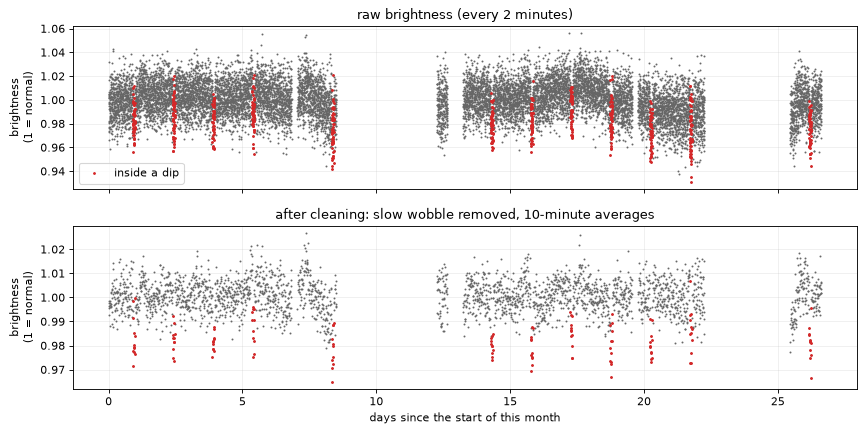

In [3]:
A = ex['A']
P, T0, DUR = A.period, A.t0, A.duration_h / 24          # days
# the sectors the search used, per example
lcs = {k: [lk.read(p, flux_column='pdcsap_flux') for p in
           m7.capped(sorted(str(p) for p in m7.RAW.glob(f'*{r.tic:016d}*')))] for k, r in ex.items()}
print(f"star A: {len(lcs['A'])} sectors (months) of data")

def near_dip(t, half):
    # True where t is within `half` days of a dip centre
    cyc = (t - T0) / P
    return np.abs(cyc - np.round(cyc)) * P < half

month = lcs['A'][0]
raw = month.remove_nans().normalize()
t_raw, f_raw = raw.time.value, raw.flux.value
t_cl, f_cl, _ = clean_and_stitch([month], bin_minutes=10, ephemeris=(P, T0, DUR))
t_cl, f_cl = np.asarray(t_cl), np.ma.filled(f_cl, np.nan)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, t, f, title in [(axes[0], t_raw, f_raw, 'raw brightness (every 2 minutes)'),
                        (axes[1], t_cl, f_cl, 'after cleaning: slow wobble removed, 10-minute averages')]:
    d = near_dip(t, DUR / 2)
    ax.plot(t - t_raw[0], f, '.', ms=1.5, color='0.4')
    ax.plot(t[d] - t_raw[0], f[d], '.', ms=3, color='tab:red', label='inside a dip')
    ax.set(title=title, ylabel='brightness\n(1 = normal)')
axes[0].legend(loc='lower left')
axes[1].set_xlabel('days since the start of this month')
plt.tight_layout(); plt.show()

The raw brightness drifts slowly (the star's own spots and rotation, and the telescope's pointing and temperature). That wobble is much slower than a dip of a couple of hours, so cleaning fits a smooth curve over about a day and a half and divides it out, skipping the dips so they aren't flattened away. What remains is a flat line at 1 with short, sharp dips: one every 1.49 days, about 2% deep.

## 3. Folding: stacking all the dips on top of each other

One dip on its own is noisy. But we know the period, so we can cut the data every 1.49 days and lay all the dips on top of each other, lined up on the dip centre. This is called *folding*. Below we use every sector (the same cleaned data the model's snapshots are built from).

102 dips with data, 22580 points inside the close-up window


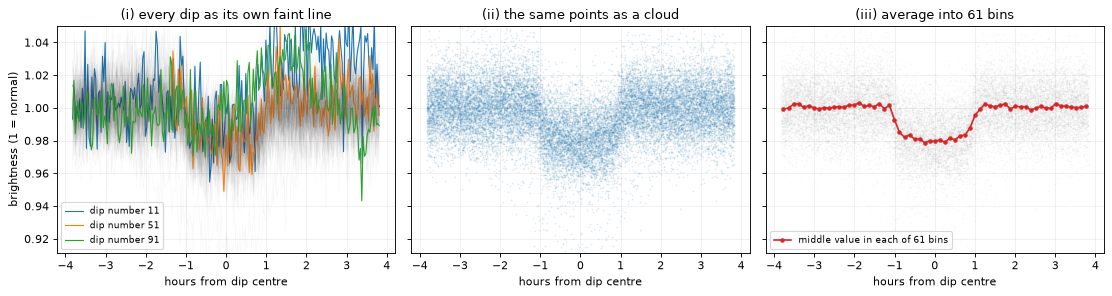

In [4]:
def cleaned_all(lc_list, period, t0, dur):
    # Same cleaning as the snapshot builder: each sector cleaned on its own, 2-minute points
    parts = [clean_and_stitch([lc], bin_minutes=2, ephemeris=(period, t0, dur)) for lc in lc_list]
    t = np.concatenate([np.asarray(p[0]) for p in parts])
    f = np.concatenate([np.ma.filled(p[1], np.nan) for p in parts])
    ok = np.isfinite(t) & np.isfinite(f)
    return t[ok], f[ok]

t, f = cleaned_all(lcs['A'], P, T0, DUR)
cycle = np.round((t - T0) / P).astype(int)   # which dip each point belongs to
dt = (t - T0) - cycle * P                    # days from the nearest dip centre
W = m7.HALF_WINDOW * DUR                     # close-up window: +/- 2 dip lengths
win = np.abs(dt) < W
print(f'{len(np.unique(cycle[win]))} dips with data, {win.sum()} points inside the close-up window')

base = np.median(f[np.abs(dt) > DUR])        # normal brightness, measured away from the dips
local_raw, _ = m7.binned(dt, f, -W, W, m7.LOCAL_BINS)       # median brightness in 61 time bins
edges = np.linspace(-W, W, m7.LOCAL_BINS + 1)
centres_h = (edges[:-1] + edges[1:]) / 2 * 24

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for n, k in enumerate(np.unique(cycle[win])):
    s = win & (cycle == k)
    axes[0].plot(dt[s] * 24, f[s], lw=.5, alpha=.04, color='0.3')
    if n in (10, 50, 90):   # three single dips, drawn strongly: each alone is mostly noise
        axes[0].plot(dt[s] * 24, f[s], lw=1, color=f'C{n // 40}', label=f'dip number {n + 1}')
axes[0].set_title('(i) every dip as its own faint line')
axes[0].legend(loc='lower left', fontsize=8)
axes[1].plot(dt[win] * 24, f[win], '.', ms=1, alpha=.15, color='tab:blue')
axes[1].set_title('(ii) the same points as a cloud')
axes[2].plot(dt[win] * 24, f[win], '.', ms=1, alpha=.06, color='0.6')
axes[2].plot(centres_h, local_raw, 'o-', ms=3, color='tab:red', label='middle value in each of 61 bins')
axes[2].set_title('(iii) average into 61 bins')
axes[2].legend(loc='lower left', fontsize=8)
axes[0].set_ylabel('brightness (1 = normal)')
for ax in axes:
    ax.set_xlabel('hours from dip centre')
axes[0].set_ylim(np.percentile(f[win], [0.2, 99.9]))
plt.tight_layout(); plt.show()

Each single dip is lost in noise, but the noise is random: some points land high, some low. Stack about a hundred dips and take the middle value in each small time slot (*bin*), and the noise cancels while the real shape stays. Result: a clean 61-point curve, the **close-up snapshot**.

The network gets it *rescaled*: normal brightness becomes 0 and the dip bottom becomes -1.

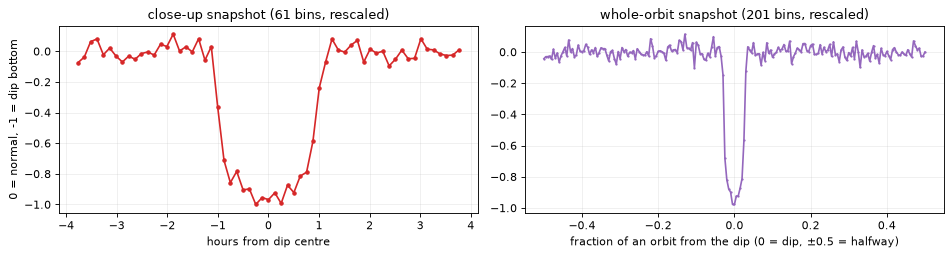

In [5]:
close_up = (local_raw - base) / (base - local_raw.min())
glob_raw, _ = m7.binned(dt / P, f, -0.5, 0.5, m7.GLOBAL_BINS)    # the whole orbit in 201 bins
whole = (glob_raw - base) / (base - local_raw.min())
assert np.allclose(close_up, npz['local'][A.view_row], atol=1e-5)  # identical to the model's input
assert np.allclose(whole, npz['global'][A.view_row], atol=1e-5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
axes[0].plot(centres_h, close_up, 'o-', ms=3, color='tab:red')
axes[0].set(title='close-up snapshot (61 bins, rescaled)', xlabel='hours from dip centre', ylabel='0 = normal, -1 = dip bottom')
axes[1].plot(np.linspace(-0.5, 0.5, m7.GLOBAL_BINS), whole, '.-', ms=2, color='tab:purple')
axes[1].set(title='whole-orbit snapshot (201 bins, rescaled)', xlabel='fraction of an orbit from the dip (0 = dip, ±0.5 = halfway)')
plt.tight_layout(); plt.show()

The **whole-orbit snapshot** is the same idea over one full orbit in 201 bins. Most of it is flat; it is there to show anything happening *away* from the dip (like the second dip of two stars). The `assert` lines check that what we just built by hand is exactly what the network is fed.

## 4. The six snapshots

Besides the whole orbit and the close-up, the model gets four more close-ups of the same 61 time slots:

- **odd** / **even**: only dips 1, 3, 5... / only dips 2, 4, 6...
- **halfway**: the same window, but centred half an orbit after the dip.
- **star position**: how far the star's measured position (on the camera) moves during the dip, as a "how significant is this shift" number. Its flat level sits a bit above 0 for every star (a side effect of how it is measured); what matters is a rise during the dip.

Here are all six for A, B and C, rebuilt from the raw files with the pipeline's own `signal_views` and checked against the stored snapshots.

signal_views output matches views.npz for all three examples


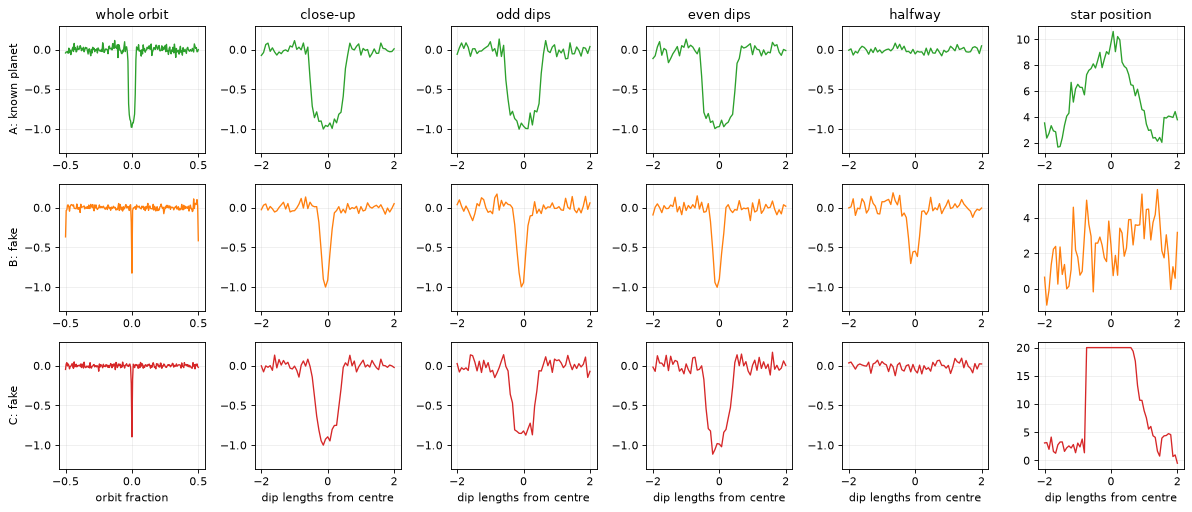

In [6]:
NAMES = {'global': 'whole orbit', 'local': 'close-up', 'odd': 'odd dips', 'even': 'even dips',
         'secondary': 'halfway', 'centroid': 'star position'}
snap = {}
for k, r in ex.items():
    snap[k], ok = m7.signal_views(lcs[k], r.period, r.t0, r.duration_h / 24)
    assert ok
    for name in NAMES:
        assert np.allclose(snap[k][name], npz[name][r.view_row], atol=1e-4), (k, name)
print('signal_views output matches views.npz for all three examples')

COLORS = {'A': 'tab:green', 'B': 'tab:orange', 'C': 'tab:red'}
fig, axes = plt.subplots(3, 6, figsize=(15, 6.5))
for i, (k, r) in enumerate(ex.items()):
    x_local = np.linspace(-2, 2, m7.LOCAL_BINS)   # in dip lengths
    for j, name in enumerate(NAMES):
        ax = axes[i, j]
        x = np.linspace(-0.5, 0.5, m7.GLOBAL_BINS) if name == 'global' else x_local
        ax.plot(x, snap[k][name], color=COLORS[k], lw=1.2)
        if name != 'centroid':
            ax.set_ylim(-1.3, 0.3)
        if i == 0:
            ax.set_title(NAMES[name])
        if i == 2:
            ax.set_xlabel('orbit fraction' if name == 'global' else 'dip lengths from centre')
    axes[i, 0].set_ylabel(f'{k}: {VERDICT[r.label].split(" (")[0]}')
plt.tight_layout(); plt.show()

| snapshot | what it shows | the fake it helps catch |
|---|---|---|
| whole orbit | the full orbit, dip in the middle | two stars: a second dip at the edges (halfway round) |
| close-up | the dip shape | two stars: a **V** shape (planets give a flat-bottomed **U**: the planet is fully in front of the star for a while) |
| odd / even | alternate dips separately | two stars of different size: every other dip has a different depth |
| halfway | half an orbit after the dip | two stars: the second star being hidden gives a small dip there |
| star position | movement of the star's measured position | a neighbouring star: the dip is really on a nearby star, so the light's centre shifts |

What to see above:
- **A** (planet): U-shaped dip with a flat floor; odd and even match; halfway is flat; a moderate position rise (about 10).
- **B** (two stars): narrower, pointier dip, and a clear **halfway dip** more than half as deep (also visible at the edges of the whole-orbit view).
- **C** (neighbour): dip looks fine, but the **position shift** jumps to the top of the scale (capped at 20) exactly during the dip.

**Why rescale?** Every flux snapshot is shifted and stretched so normal = 0 and dip bottom = -1. A 2% dip and a 0.1% dip then look the same size, so the network can only judge **shape**, not size. (Size is given to it separately, as a measurement.)

## 5. The average planet vs the average fake

Average each snapshot over all NASA planets and all NASA fakes in the hard set.

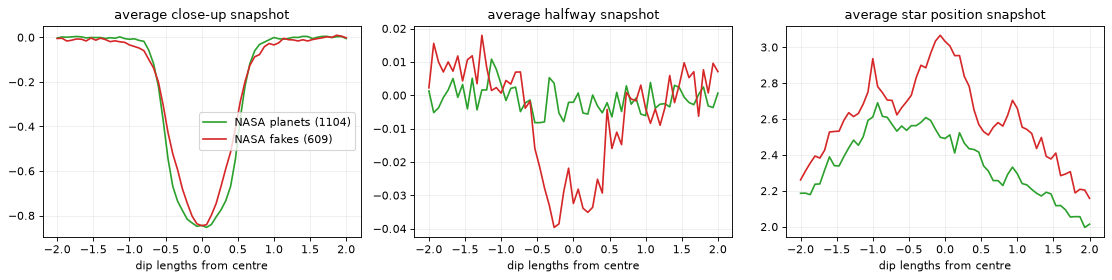

In [7]:
x_local = np.linspace(-2, 2, m7.LOCAL_BINS)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for name, ax in zip(['local', 'secondary', 'centroid'], axes):
    for y, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
        rows = hard.view_row[hard.y == y].values
        ax.plot(x_local, npz[name][rows].mean(0), color=c, label=f'{lab} ({len(rows)})')
    ax.set(title=f'average {NAMES[name]} snapshot', xlabel='dip lengths from centre')
axes[0].legend()
plt.tight_layout(); plt.show()

- **Close-up**: the average planet has a slightly wider, flatter bottom (U); the average fake narrows more to a point (V), with wider sloping sides.
- **Halfway**: planets are flat; fakes dip on average, from the two-star pairs among them.
- **Star position**: fakes shift more during the dip. Planets also show some shift (a deep dip on a star with neighbours nudges the measured centre), so it's a matter of *how much*, which is exactly what a learned model is good at weighing.

These are averages; individual fakes and planets overlap a lot, which is why this is the hard set.

## 6. The 12 measurements, and why the model gets both

Along with the snapshots, the network gets 12 numbers measured by the search. (Counts that grow with more data are turned into per-dip values, so the model can't just learn "stars watched longer are planets".)

In [8]:
PLAIN = {
    'period': 'time between dips (days)',
    'duration_h': 'dip length (hours)',
    'depth_ppm': 'dip depth (parts per million)',
    'sde_per_transit': 'how much this period beats all others tried (per dip)',
    'depth_snr_per_transit': 'stands out from noise (per dip)',
    'pink_snr_per_transit': 'stands out from slow, wavy noise (per dip)',
    'odd_even_sigma': 'odd/even depth difference',
    'secondary_snr': 'halfway dip strength',
    'centroid_snr': 'star position shift',
    'transits_per_sector': 'dips seen per month',
    'significant_event_fraction': 'share of dips that are clear on their own',
    'chunk_fraction': 'share of separate data stretches where it was found',
}
assert list(PLAIN) == m6.DIP_FEATURES
meas = pd.DataFrame({f'{k} ({VERDICT[r.label].split(" (")[0]})': [r[c] for c in PLAIN] for k, r in ex.items()},
                    index=list(PLAIN.values()))
display(meas.round(2))

,A (known planet),B (fake),C (fake)
time between dips (days),1.49,13.71,29.02
dip length (hours),1.91,5.81,7.37
dip depth (parts per million),19146.50,1518.39,1144.82
how much this period beats all others tried (per dip),3.32,6.11,9.02
stands out from noise (per dip),10.22,15.21,16.69
"stands out from slow, wavy noise (per dip)",6.69,11.45,13.41
odd/even depth difference,2.60,0.08,3.15
halfway dip strength,3.11,20.09,1.94
star position shift,6.26,1.70,98.03
dips seen per month,16.17,1.67,0.88


The measurements match the pictures: B has a strong halfway dip (about 20), C a huge position shift (about 98). A's odd/even and halfway numbers are small.

**Why both inputs?**
- The snapshots are rescaled, so they **lose size and noise level**: a crisp 2% dip and a barely-there 0.05% dip both reach -1. The measurements keep depth, length, period and how far the dip stands out from the noise.
- The measurements only **summarise** shape in a few numbers (e.g. one number for "halfway dip"). The snapshots keep the full shape: U vs V, slopes, where a shift happens.

The proof is in the scores. *ROC AUC* measures ranking: pick a random planet and a random fake; how often does the model score the planet higher? 0.5 = coin flip, 1 = perfect.

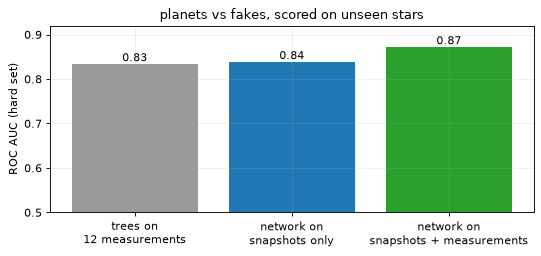

Letting through as many fakes as the old fixed rules do, the old rules catch 60% of planets; trees on 12 measurements: 81%, network on snapshots only: 84%, network on snapshots + measurements: 87%


In [9]:
h = df.hard.values
results = {}
for col, name in [('gbt', 'trees on\n12 measurements'), ('views', 'network on\nsnapshots only'),
                  ('views_features', 'network on\nsnapshots + measurements')]:
    mean, _ = m6.fold_stats(df, df[col].values, df.fold.values, h)
    results[name] = mean
fig, ax = plt.subplots(figsize=(7, 3.3))
bars = ax.bar(list(results), [m.roc_auc for m in results.values()], color=['0.6', 'tab:blue', 'tab:green'])
ax.bar_label(bars, fmt='%.2f')
ax.set(ylim=(0.5, 0.92), ylabel='ROC AUC (hard set)', title='planets vs fakes, scored on unseen stars')
plt.tight_layout(); plt.show()
rules = next(iter(results.values())).rules_planets_caught
print(f"Letting through as many fakes as the old fixed rules do, the old rules catch {rules:.0%} of planets; "
      + ', '.join(f"{n.replace(chr(10), ' ')}: {m.model_planets_caught:.0%}" for n, m in results.items()))

Each input alone is about as good as the other (0.83 vs 0.84); together they reach 0.87, because each carries information the other lacks. Example C shows this: the network on snapshots alone gave it 0.50 (unsure); with the measurements added, 0.0004.

## 7. Inside the network

The model is a *convolutional neural network* (CNN): instead of looking at all 61 points at once, it slides many small **pattern detectors** (5 points wide) along each snapshot and notes where each one matches.

Its layout, in plain words:
1. **Two readers.** One reads the whole-orbit snapshot. The other reads the five close-ups (close-up, odd, even, halfway, star position) stacked together, so it can compare them slot by slot.
2. **Pattern detectors, in layers.** Each reader has layers of detectors. The first layer spots tiny patterns (a slope, an edge). Later layers combine those into bigger ones. After each pair of layers the curve is shrunk by half, keeping the strongest responses.
3. **Summary.** Each detector's strongest response in each quarter of the snapshot is kept: 64×4 numbers from the whole orbit, 32×4 from the close-ups.
4. **Combine.** Those are joined with the 12 measurements (plus 12 "this measurement was missing" flags) and passed through one hidden layer of 128 units to a single score from 0 to 1.

We train one copy now, on CPU, using every star **except** group 0, where our three examples live. So A, B and C are unseen.

In [10]:
views = {k: np.clip(npz[k][df.view_row], -10, 10) for k in ['global'] + m8.LOCAL}
g = torch.as_tensor(views['global'][:, None])                   # whole orbit: 1 channel x 201
l = torch.as_tensor(np.stack([views[k] for k in m8.LOCAL], 1))  # close-ups: 5 channels x 61
y = torch.as_tensor(df.y.values.astype(np.float32))
TEST_GROUP = ex['A'].fold
train = np.flatnonzero(df.fold.values != TEST_GROUP)
x = torch.as_tensor(m8.features(df, train))                     # 12 measurements + 12 missing flags
fit, val = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0)
                .split(train, groups=df.tic.values[train]))    # 15% of training stars decide when to stop

t_start = time.time()
net = m8.train_one(g, l, x, y, train[fit], train[val], seed=0).eval()
print(f'trained on {len(train)} dips in {time.time() - t_start:.0f} s; '
      f'{sum(p.numel() for p in net.parameters()):,} adjustable numbers in the network')
print(net)

trained on 2558 dips in 11 s; 101,921 adjustable numbers in the network
ShapeNet(
  (glob): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): Conv1d(16, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (6): ReLU()
    (7): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (8): ReLU()
    (9): MaxPool1d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (11): ReLU()
    (12): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (13): ReLU()
    (14): MaxPool1d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): AdaptiveMaxPool1d(output_size=4)
    (16): Flatten(start_dim=1, end_dim=-1)
  )
  (loc): Sequential(
    (0): Conv1d(5, 

### First-layer pattern detectors

Each first-layer detector in the close-up reader is a set of 5 weights per snapshot. Here are the weights it applies to the **close-up** snapshot, for the 4 detectors that lean on the close-up the most. They are simple shapes: a step, a notch, a trough. Nothing here "knows" about planets; that comes from combining many of them in later layers.

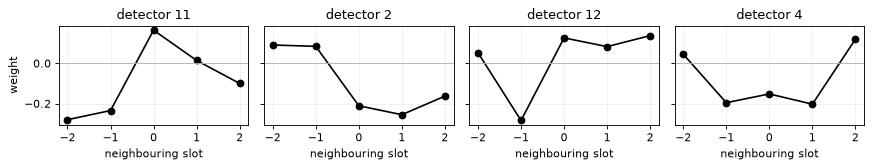

In [11]:
conv1 = net.loc[0]                              # first layer of the close-up reader
W = conv1.weight.detach()[:, 0]                 # weights applied to the close-up snapshot: 16 x 5
pick = torch.argsort(W.norm(dim=1), descending=True)[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(11, 2.2), sharey=True)
for ax, i in zip(axes, pick):
    ax.plot(range(-2, 3), W[i], 'o-', color='k')
    ax.axhline(0, color='0.7', lw=.8)
    ax.set(title=f'detector {i}', xticks=range(-2, 3), xlabel='neighbouring slot')
axes[0].set_ylabel('weight')
plt.tight_layout(); plt.show()

### Where on the dip each detector lights up

Slide each detector along the close-up snapshot of A (planet) and B (two stars). The response at each slot is how well the 5 points around it match the detector (negative matches are set to 0). We only use the close-up part of each detector here, to keep the picture readable.

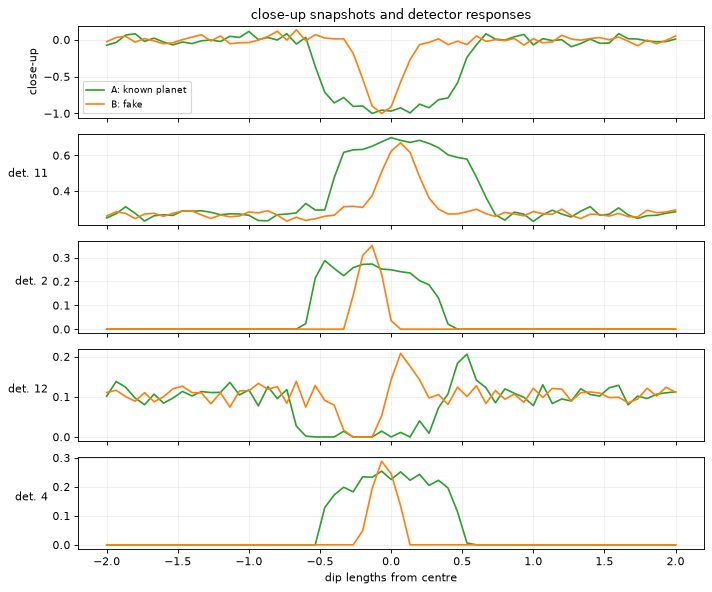

In [12]:
def response(k):
    s = torch.as_tensor(snap[k]['local'], dtype=torch.float32)[None, None]
    return torch.relu(torch.nn.functional.conv1d(s, W[:, None], conv1.bias.detach(), padding=2))[0]

fig, axes = plt.subplots(len(pick) + 1, 1, figsize=(9, 7.5), sharex=True)
for k in ['A', 'B']:
    axes[0].plot(x_local, snap[k]['local'], color=COLORS[k], label=f'{k}: {VERDICT[ex[k].label].split(" (")[0]}')
    r = response(k)
    for ax, i in zip(axes[1:], pick):
        ax.plot(x_local, r[i], color=COLORS[k])
        ax.set_ylabel(f'det. {i}', rotation=0, ha='right')
axes[0].set(title='close-up snapshots and detector responses', ylabel='close-up')
axes[0].legend(loc='lower left', fontsize=8)
axes[-1].set_xlabel('dip lengths from centre')
plt.tight_layout(); plt.show()

Most of these detectors fire wherever the snapshot is low, i.e. inside the dip, and some fire more at one edge. For the planet (A) the response is a **wide plateau** (the U's flat floor); for the two-star pair (B) it is a **narrow spike** (its pointy bottom). So even the first layer turns the shape into "how wide and flat is the low part". Later layers combine such responses, across all five close-ups, into evidence for planet or fake; that part is spread over thousands of weights and can't be drawn as one picture.

### What each input contributes

Score each example three ways: with everything; with its snapshots swapped for the **average snapshots** of all training dips; and with its measurements swapped for **average values**. Swapping in averages (rather than, say, a flat line the network never saw in training) asks a fair question: what does this example's own shape, or its own numbers, add?

In [13]:
g_avg, l_avg = g[train].mean(0, keepdim=True), l[train].mean(0, keepdim=True)   # average training snapshots
x_avg = torch.zeros(1, x.shape[1])   # measurements are standardized on the training dips, so 0 = average

def score(i, own_snapshots=True, own_measurements=True):
    with torch.no_grad():
        return torch.sigmoid(net(g[i] if own_snapshots else g_avg, l[i] if own_snapshots else l_avg,
                                 x[i] if own_measurements else x_avg)).item()

rows = {}
for k, r in ex.items():
    i = [df.index[(df.tic == r.tic) & (df.signal == r.signal)][0]]
    rows[f'{k} ({VERDICT[r.label].split(" (")[0]})'] = {
        'full score': score(i),
        'average snapshots instead': score(i, own_snapshots=False),
        'average measurements instead': score(i, own_measurements=False)}
display(pd.DataFrame(rows).T.round(4))

test = np.flatnonzero((df.fold.values == TEST_GROUP) & h)
with torch.no_grad():
    p = torch.sigmoid(net(g[test], l[test], x[test])).numpy()
from sklearn.metrics import roc_auc_score
print(f'this one network on the unseen group, hard set: ROC AUC {roc_auc_score(df.y.values[test], p):.2f}')

,full score,average snapshots instead,average measurements instead
A (known planet),0.9583,0.2813,0.9525
B (fake),0.0106,0.0145,0.3431
C (fake),0.0003,0.0001,0.8488


this one network on the unseen group, hard set: ROC AUC 0.88


How to read this:
- **A (planet)**: with average snapshots the score falls from about 0.96 to about 0.28; with average measurements it barely moves. A's own dip shape is what convinces the network (the trees, which only see measurements, scored it 0.06).
- **B (two stars)**: the snapshots alone already lean fake (about 0.34); adding the measurements (strong halfway dip, among others) pushes it to about 0.01.
- **C (neighbour)**: a surprise. With its own snapshots but average measurements, the score jumps to about 0.85: even with the position snapshot maxed out, the pictures alone don't reject it. Its measurements (huge position-shift number, among others) are what pull it to near 0. This single network leans on the position *number* more than the position *picture*.

This one network is trained once with one random start; the stored scores in section 1 average 5 starts per group, so the numbers differ a little.

## Recap

- The search finds a repeating dip; the question is whether it's a planet or a fake.
- **Folding** stacks every dip on the period, so random noise averages out and the true shape shows.
- The **6 snapshots** are folded pictures: whole orbit, close-up, odd dips, even dips, halfway point, star position. Each one targets a kind of fake: V shape, unequal dips, halfway dip (two stars) or position shift (neighbouring star).
- Snapshots are **rescaled** (normal = 0, bottom = -1), so they show shape only, not size.
- The **12 measurements** carry what rescaling throws away (depth, length, noise level, how strongly the period was found) plus one-number summaries of the warning signs.
- The **network** slides small pattern detectors (edges, slopes) along the snapshots, builds them into bigger patterns, adds the measurements and outputs a score from 0 to 1.
- Each input alone ranks planets above fakes about equally well (0.83 to 0.84); together they reach 0.87, because each fills in what the other misses.

In [14]:
print(f'notebook ran in {time.time() - START:.0f} s')

notebook ran in 50 s
